# Confidence score distribution (adaptive-K retrieval)

학습한 CLIP(`runs/clip_hardmut/best.pt`)으로 각 쿼리 MRI의 **소견서 DB 유사도 분포**를 뽑고,
분포 기반 adaptive K와 confidence score를 계산한다.

- 쿼리 벡터 `q` = 이미지 임베딩 (현재 데이터에 brief findings 없음 → image-only)
- 소견서 DB = train 811 case의 소견서 (val/test 쿼리의 정답 소견서는 DB에 없음 = 실제 사용 상황)
- 정렬된 유사도 $s_{(1)} \ge \dots \ge s_{(N)}$, $\Delta_i = s_{(i)} - s_{(i+1)}$
- $K^* = \arg\max_{K_{min} \le i \le K_{max}} \Delta_i$,  $c = \Delta_{K^*} / (\sigma(s) + \epsilon)$

DB에 정답이 없으므로 검색 품질은 대리 지표로 본다.
- **IDH P@K**: top-K 중 쿼리와 IDH 그룹(WT=label 2 / MUT=label 0,1)이 같은 비율
- **Label P@K**: top-K 중 label이 같은 비율
- **RepSim@K**: 쿼리의 실제 소견서와 top-K 소견서 사이 텍스트 임베딩 cosine 평균 (내용이 얼마나 비슷한가)

In [1]:
import os
os.environ.setdefault("CUDA_DEVICE_ORDER", "PCI_BUS_ID")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")   # GPU 1만 사용
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from transformers import CLIPTokenizer

from clip_mri_report import (MRIReportDataset, VolumeLoader, build_model_from_args, collate,
                             encode_loader, encode_texts, load_data)

RUN = "runs/clip_hardmut"
CKPT = f"{RUN}/best.pt"
OUT = f"{RUN}/dist"            # 그림/CSV 저장 위치
os.makedirs(OUT, exist_ok=True)

K_MIN, K_MAX, EPS = 1, 10, 1e-6   # adaptive K 탐색 범위
FIXED_K = 5                       # baseline: fixed top-K

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.set_per_process_memory_fraction(min(1.0, 24 / 47.5)) if device.type == "cuda" else None
print(device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

/home/dongik/.conda/envs/rrg-clip/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda NVIDIA RTX A6000


In [2]:
# 그림 스타일 (plot_tb.py와 동일 팔레트)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
SURFACE, TEXT, TEXT2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "text.color": TEXT, "axes.titlecolor": TEXT, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 11, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 10, "lines.linewidth": 2,
    "font.family": "DejaVu Sans", "figure.dpi": 110,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{OUT}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. 모델 로드 + 소견서 DB / 쿼리 임베딩

In [3]:
ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
a = ckpt["args"]
model = build_model_from_args(a)
model.load_state_dict(ckpt["model"])
model.to(device).eval()
tokenizer = CLIPTokenizer.from_pretrained(a["clip_model"])

rec_by_id, split, _ = load_data(a, json.load(open(f"{RUN}/split.json")))
bank_ids = split["train"]
bank = [rec_by_id[i] for i in bank_ids]
bank_emb = encode_texts(model, tokenizer, [r["report"] for r in bank], a["max_text_len"], device)
bank_label = np.array([r["label"] for r in bank])
print("report DB:", bank_emb.shape)

loader = VolumeLoader(a["modalities"], a["num_slices"], a["fusion"], train=False)
Q = {}
for name in ["val", "test"]:
    recs = [rec_by_id[i] for i in split[name]]
    dl = DataLoader(MRIReportDataset(recs, a["image_root"], loader), batch_size=16,
                    num_workers=8, collate_fn=collate)
    img, ids, labels, reports = encode_loader(model, dl, device)
    gt_txt = encode_texts(model, tokenizer, reports, a["max_text_len"], device)
    Q[name] = dict(img=img, ids=ids, label=labels.numpy(), gt_txt=gt_txt)
    print(name, "queries:", img.shape)

/home/dongik/Workspace/rrg-clip/clip_mri_report.py:249: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.aggregator = nn.TransformerEncoder(layer, num_layers=agg_layers)


report DB: torch.Size([811, 512])


encode images:   0%|          | 0/6 [00:00<?, ?it/s]

encode images:  17%|█▋        | 1/6 [00:01<00:07,  1.46s/it]

encode images:  50%|█████     | 3/6 [00:01<00:01,  2.24it/s]

encode images:  67%|██████▋   | 4/6 [00:01<00:00,  2.93it/s]

... (8 outputs left out)

encode images:  71%|███████▏  | 5/7 [00:01<00:00,  4.08it/s]

encode images:  86%|████████▌ | 6/7 [00:02<00:00,  4.75it/s]

encode images: 100%|██████████| 7/7 [00:02<00:00,  5.36it/s]

test queries: torch.Size([100, 512])


## 2. Adaptive K*와 confidence c 계산

In [4]:
def adaptive_k(s_sorted, k_min=K_MIN, k_max=K_MAX, eps=EPS):
    """s_sorted: 내림차순 유사도 [N]. Δ_i = s(i) - s(i+1), i는 1-based."""
    d = s_sorted[:-1] - s_sorted[1:]                 # d[i-1] = Δ_i
    win = d[k_min - 1:k_max]
    k_star = int(np.argmax(win)) + k_min
    gap = float(d[k_star - 1])
    return k_star, gap, gap / (float(s_sorted.std()) + eps)

def idh(lbl):
    return (np.asarray(lbl) == 2).astype(int)        # 1 = IDH-wildtype, 0 = IDH-mutant

txt_bank = bank_emb                                   # 소견서 텍스트 임베딩 (RepSim 계산용)
rows, SIMS = [], {}
for name, q in Q.items():
    sim = (q["img"] @ bank_emb.t()).cpu().numpy()     # [Nq, N] cosine
    rep = (q["gt_txt"] @ txt_bank.t()).cpu().numpy()  # 실제 소견서 vs DB 소견서
    SIMS[name] = sim
    for i, cid in enumerate(q["ids"]):
        order = np.argsort(-sim[i])
        s = sim[i][order]
        k, gap, c = adaptive_k(s)
        lab = q["label"][i]
        def stats(K):
            top = order[:K]
            return dict(idh=(idh(bank_label[top]) == idh(lab)).mean() * 100,
                        lab=(bank_label[top] == lab).mean() * 100,
                        rep=rep[i][top].mean())
        ad, fx = stats(k), stats(FIXED_K)
        rows.append(dict(split=name, id=cid, label=int(lab), k_star=k, gap=gap, sigma=s.std(), c=c,
                         s1=s[0], s2=s[1], s_mean=s.mean(),
                         idh_pK=ad["idh"], lab_pK=ad["lab"], rep_K=ad["rep"],
                         idh_p5=fx["idh"], lab_p5=fx["lab"], rep_5=fx["rep"],
                         rep_oracle=rep[i].max(), idh_top1=ad["idh"] if k == 1 else stats(1)["idh"]))
df = pd.DataFrame(rows)
df.to_csv(f"{OUT}/confidence_scores.csv", index=False)
df.groupby("split")[["k_star", "gap", "sigma", "c", "s1", "s_mean"]].describe().T.round(4)

split             test      val
k_star count  100.0000  90.0000
       mean     2.5900   2.9778
       std      2.0305   2.5527
       min      1.0000   1.0000
       25%      1.0000   1.0000
       50%      2.0000   2.0000
       75%      3.2500   4.0000
       max      9.0000  10.0000
gap    count  100.0000  90.0000
       mean     0.0204   0.0191
       std      0.0125   0.0105
       min      0.0022   0.0050
       25%      0.0127   0.0108
       50%      0.0158   0.0160
       75%      0.0260   0.0255
       max      0.0613   0.0517
sigma  count  100.0000  90.0000
       mean     0.0752   0.0752
       std      0.0062   0.0059
       min      0.0630   0.0566
       25%      0.0713   0.0722
       50%      0.0751   0.0756
       75%      0.0787   0.0787
       max      0.0938   0.0922
c      count  100.0000  90.0000
       mean     0.2727   0.2560
       std      0.1677   0.1404
       min      0.0287   0.0704
       25%      0.1617   0.1476
       50%      0.2102   0.2143
       75%      0.3510   0.3540
       max      0.8693   0.6557
s1     count  100.0000  90.0000
       mean     0.2316   0.2326
       std      0.0277   0.0280
       min      0.1738   0.1695
       25%      0.2122   0.2116
       50%      0.2296   0.2328
       75%      0.2531   0.2504
       max      0.2835   0.2923
s_mean count  100.0000  90.0000
       mean     0.0167   0.0171
       std      0.0223   0.0235
       min     -0.0320  -0.0425
       25%      0.0018   0.0011
       50%      0.0166   0.0202
       75%      0.0329   0.0363
       max      0.0630   0.0635

## 3. 유사도 분포 예시: Case A (뾰족) vs Case B (평평)

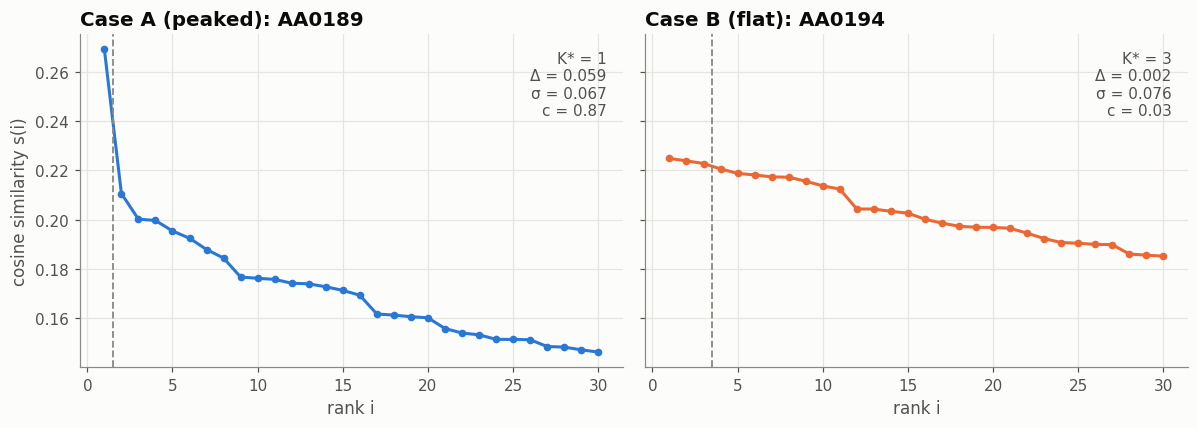

In [5]:
def plot_curve(ax, name, cid, title, color, n_show=30):
    i = Q[name]["ids"].index(cid)
    s = np.sort(SIMS[name][i])[::-1]
    r = df[(df.split == name) & (df.id == cid)].iloc[0]
    x = np.arange(1, n_show + 1)
    ax.plot(x, s[:n_show], color=color, marker="o", ms=4)
    ax.axvline(r.k_star + 0.5, color=MUTED, ls="--", lw=1.2)
    ax.annotate(f"K* = {r.k_star}\nΔ = {r.gap:.3f}\nσ = {r.sigma:.3f}\nc = {r.c:.2f}",
                xy=(0.97, 0.95), xycoords="axes fraction", ha="right", va="top", color=TEXT2)
    ax.set_title(title)
    ax.set_xlabel("rank i")

hi = df[df.split == "test"].sort_values("c").iloc[-1]
lo = df[df.split == "test"].sort_values("c").iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
plot_curve(axes[0], "test", hi.id, f"Case A (peaked): {hi.id}", SERIES[0])
plot_curve(axes[1], "test", lo.id, f"Case B (flat): {lo.id}", SERIES[1])
axes[0].set_ylabel("cosine similarity s(i)")
save(fig, "01_similarity_curves_example")

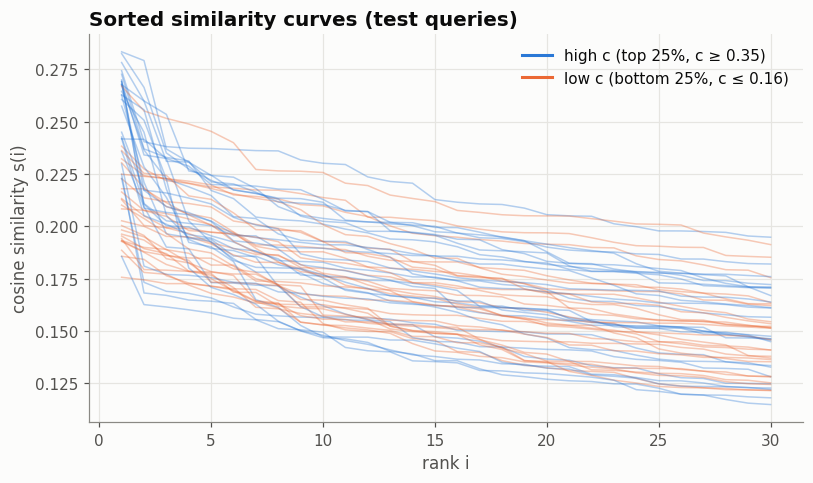

In [6]:
# 전체 쿼리의 top-30 정렬 유사도 곡선: c 상위 25% vs 하위 25%
fig, ax = plt.subplots(figsize=(7.5, 4.5))
t = df[df.split == "test"]
q_hi, q_lo = t.c.quantile(0.75), t.c.quantile(0.25)
for _, r in t.iterrows():
    i = Q["test"]["ids"].index(r.id)
    s = np.sort(SIMS["test"][i])[::-1][:30]
    if r.c >= q_hi:
        ax.plot(range(1, 31), s, color=SERIES[0], alpha=0.35, lw=1)
    elif r.c <= q_lo:
        ax.plot(range(1, 31), s, color=SERIES[1], alpha=0.35, lw=1)
ax.plot([], [], color=SERIES[0], label=f"high c (top 25%, c ≥ {q_hi:.2f})")
ax.plot([], [], color=SERIES[1], label=f"low c (bottom 25%, c ≤ {q_lo:.2f})")
ax.legend()
ax.set_title("Sorted similarity curves (test queries)")
ax.set_xlabel("rank i"); ax.set_ylabel("cosine similarity s(i)")
save(fig, "02_similarity_curves_by_confidence")

## 4. Confidence score c 분포 / K* 분포

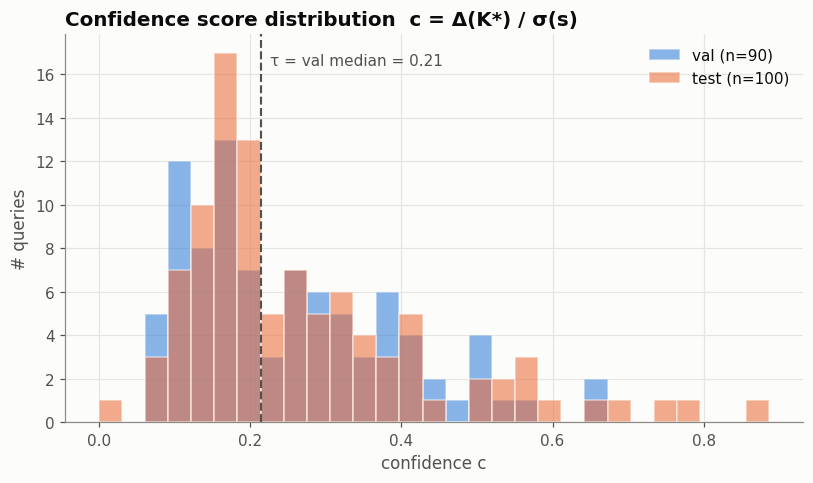

In [7]:
tau = df[df.split == "val"].c.median()   # τ 후보: validation median (임시)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
bins = np.linspace(0, df.c.max() * 1.02, 30)
for j, name in enumerate(["val", "test"]):
    ax.hist(df[df.split == name].c, bins=bins, color=SERIES[j], alpha=0.55,
            label=f"{name} (n={int((df.split == name).sum())})", edgecolor=SURFACE, linewidth=1)
ax.axvline(tau, color=TEXT2, ls="--", lw=1.4)
ax.annotate(f"τ = val median = {tau:.2f}", xy=(tau, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", color=TEXT2)
ax.legend(loc="upper right")
ax.set_title("Confidence score distribution  c = Δ(K*) / σ(s)")
ax.set_xlabel("confidence c"); ax.set_ylabel("# queries")
save(fig, "03_confidence_hist")

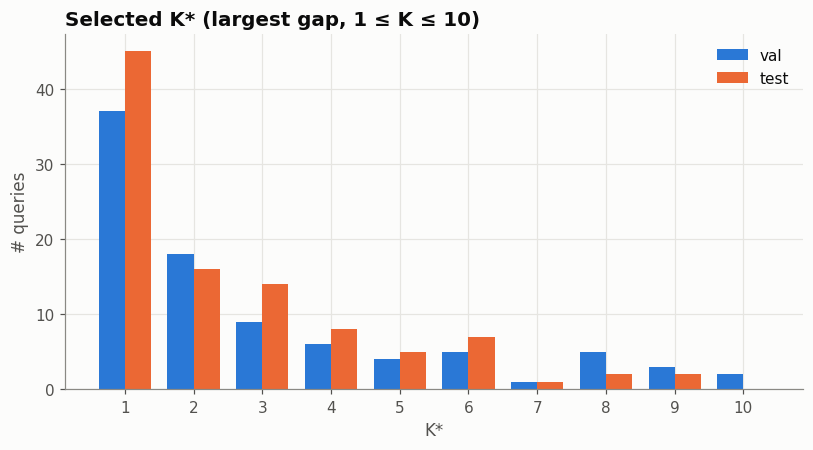

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ks = np.arange(K_MIN, K_MAX + 1)
w = 0.38
for j, name in enumerate(["val", "test"]):
    cnt = df[df.split == name].k_star.value_counts().reindex(ks, fill_value=0)
    ax.bar(ks + (j - 0.5) * w, cnt.values, width=w, color=SERIES[j], label=name)
ax.set_xticks(ks)
ax.legend()
ax.set_title(f"Selected K* (largest gap, {K_MIN} ≤ K ≤ {K_MAX})")
ax.set_xlabel("K*"); ax.set_ylabel("# queries")
save(fig, "04_kstar_hist")

## 5. Confidence가 높으면 검색이 실제로 더 정확한가?

In [9]:
def spearman(x, y):
    rx, ry = pd.Series(x).rank().values, pd.Series(y).rank().values
    return np.corrcoef(rx, ry)[0, 1]

d = df.copy()
d["c_group"] = pd.qcut(d.c, 3, labels=["low c", "mid c", "high c"])
summ = d.groupby("c_group", observed=True).agg(
    n=("c", "size"), c_mean=("c", "mean"), K_mean=("k_star", "mean"),
    idh_top1=("idh_top1", "mean"), idh_pK=("idh_pK", "mean"), idh_p5=("idh_p5", "mean"),
    lab_pK=("lab_pK", "mean"), rep_K=("rep_K", "mean"), rep_5=("rep_5", "mean"),
    rep_oracle=("rep_oracle", "mean")).round(3)
print("Spearman(c, ·)  [val+test, n=%d]" % len(d))
for col in ["idh_top1", "idh_pK", "idh_p5", "lab_pK", "rep_K", "rep_5", "rep_oracle", "s1"]:
    print(f"  {col:10s} {spearman(d.c, d[col]):+.3f}")
summ

Spearman(c, ·)  [val+test, n=190]
  idh_top1   +0.085
  idh_pK     +0.150
  idh_p5     +0.060
  lab_pK     +0.027
  rep_K      -0.145
  rep_5      -0.101
  rep_oracle -0.028
  s1         +0.565


,n,c_mean,K_mean,idh_top1,idh_pK,idh_p5,lab_pK,rep_K,rep_5,rep_oracle
c_group,,,,,,,,,,
low c,64,0.128,4.312,84.375,84.453,86.562,80.178,0.539,0.537,0.741
mid c,62,0.221,2.484,83.871,86.559,82.581,77.016,0.516,0.520,0.730
high c,64,0.444,1.516,93.750,94.010,92.188,79.948,0.517,0.523,0.731


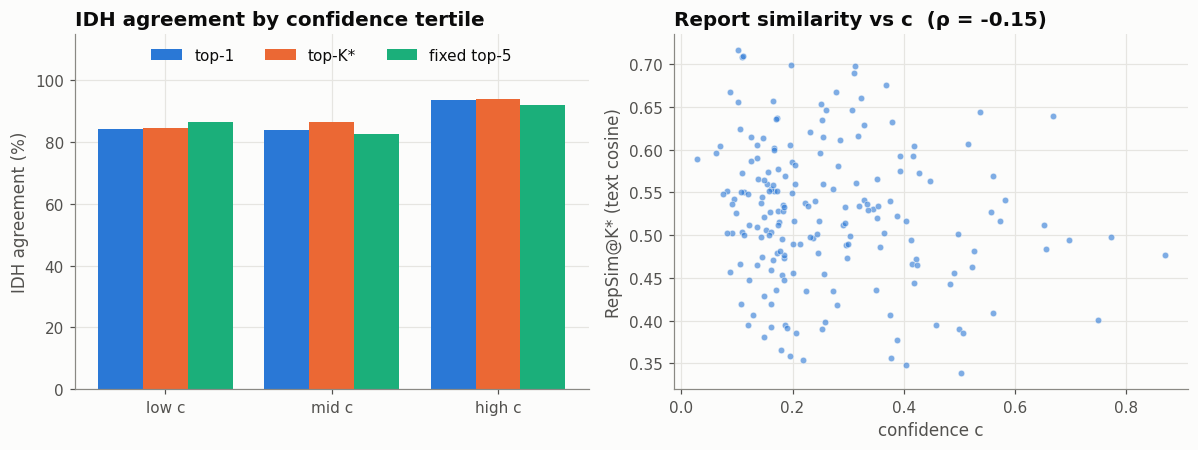

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.arange(3)
for j, (col, lab) in enumerate([("idh_top1", "top-1"), ("idh_pK", "top-K*"), ("idh_p5", "fixed top-5")]):
    axes[0].bar(x + (j - 1) * 0.27, summ[col].values, width=0.27, color=SERIES[j], label=lab)
axes[0].set_xticks(x, summ.index.astype(str))
axes[0].set_ylim(0, 115); axes[0].set_yticks(range(0, 101, 20))
axes[0].set_ylabel("IDH agreement (%)")
axes[0].set_title("IDH agreement by confidence tertile")
axes[0].legend(loc="upper center", ncol=3)

axes[1].scatter(d.c, d.rep_K, s=18, color=SERIES[0], alpha=0.6, edgecolor=SURFACE, linewidth=0.5)
axes[1].set_xlabel("confidence c")
axes[1].set_ylabel("RepSim@K* (text cosine)")
axes[1].set_title(f"Report similarity vs c  (ρ = {spearman(d.c, d.rep_K):+.2f})")
save(fig, "05_confidence_vs_quality")

## 6. 결과 저장
- `runs/clip_hardmut/dist/confidence_scores.csv`: 쿼리별 K*, Δ, σ, c, 품질 지표
- `runs/clip_hardmut/dist/*.png`: 그림

In [11]:
summ.to_csv(f"{OUT}/confidence_tertile_summary.csv")
print(sorted(os.listdir(OUT)))

['01_similarity_curves_example.png', '02_similarity_curves_by_confidence.png', '03_confidence_hist.png', '04_kstar_hist.png', '05_confidence_vs_quality.png', '06_ablation_kmin.png', 'ablation_kmin_scores.csv', 'ablation_kmin_summary.csv', 'ablation_kmin_tertile.csv', 'confidence_scores.csv', 'confidence_tertile_summary.csv']


## 7. Ablation: K_min = 1 vs 2

K_min=1이면 K*=1(1등 바로 뒤의 틈)이 43%를 차지한다. 최소 2개를 넘기도록 K_min=2로 바꾸면
K*, c 분포와 c의 품질 예측력이 어떻게 달라지는지 비교한다. (K_max=10, τ = 각 설정의 val median)

In [12]:
REP = {name: (q["gt_txt"] @ txt_bank.t()).cpu().numpy() for name, q in Q.items()}

def run_setting(k_min, k_max=K_MAX):
    out = []
    for name, q in Q.items():
        for i, cid in enumerate(q["ids"]):
            order = np.argsort(-SIMS[name][i])
            s = SIMS[name][i][order]
            k, gap, c = adaptive_k(s, k_min, k_max)
            lab = q["label"][i]
            top = order[:k]
            out.append(dict(split=name, id=cid, k_star=k, gap=gap, c=c,
                            idh_pK=(idh(bank_label[top]) == idh(lab)).mean() * 100,
                            lab_pK=(bank_label[top] == lab).mean() * 100,
                            rep_K=REP[name][i][top].mean()))
    r = pd.DataFrame(out)
    tau_k = r[r.split == "val"].c.median()
    r["confident"] = r.c >= tau_k
    r["c_group"] = pd.qcut(r.c, 3, labels=["low c", "mid c", "high c"])
    return r, tau_k

ABL = {km: run_setting(km) for km in [1, 2]}
pd.concat([ABL[1][0].assign(K_min=1), ABL[2][0].assign(K_min=2)]).to_csv(
    f"{OUT}/ablation_kmin_scores.csv", index=False)

rows = []
for km, (r, tau_k) in ABL.items():
    for name in ["val", "test", "all"]:
        x = r if name == "all" else r[r.split == name]
        conf, unc = x[x.confident], x[~x.confident]
        rows.append({"K_min": km, "split": name, "n": len(x), "mean K*": x.k_star.mean(),
                     "K*=K_min %": (x.k_star == km).mean() * 100, "c median": x.c.median(), "τ": tau_k,
                     "IDH@K*": x.idh_pK.mean(), "label@K*": x.lab_pK.mean(), "RepSim@K*": x.rep_K.mean(),
                     "IDH conf": conf.idh_pK.mean(), "IDH unc": unc.idh_pK.mean(),
                     "ρ(c, IDH@K*)": spearman(x.c, x.idh_pK), "ρ(c, RepSim)": spearman(x.c, x.rep_K)})
abl = pd.DataFrame(rows).round(3)
abl.to_csv(f"{OUT}/ablation_kmin_summary.csv", index=False)
abl

,K_min,split,n,mean K*,K*=K_min %,c median,τ,IDH@K*,label@K*,RepSim@K*,IDH conf,IDH unc,"ρ(c, IDH@K*)","ρ(c, RepSim)"
0,1,val,90,2.978,41.111,0.214,0.214,93.821,81.321,0.539,96.296,91.346,0.148,-0.152
1,1,test,100,2.590,45.000,0.210,0.214,83.444,77.042,0.510,90.136,77.015,0.163,-0.122
2,1,all,190,2.774,43.158,0.210,0.214,88.360,79.069,0.524,93.085,83.733,0.150,-0.145
3,2,val,90,4.000,30.000,0.155,0.155,92.697,80.091,0.533,93.519,91.875,-0.043,-0.192
4,2,test,100,4.300,26.000,0.162,0.155,81.949,76.594,0.522,85.725,77.516,0.081,0.079
5,2,all,190,4.158,27.895,0.161,0.155,87.040,78.250,0.527,89.268,84.616,0.028,-0.068


In [13]:
# c 3등분 그룹별 top-K* IDH 일치율 (val+test)
tert = pd.concat({f"K_min={km}": r.groupby("c_group", observed=True).agg(
    n=("c", "size"), c_mean=("c", "mean"), K_mean=("k_star", "mean"), idh_pK=("idh_pK", "mean"),
    lab_pK=("lab_pK", "mean"), rep_K=("rep_K", "mean")) for km, (r, _) in ABL.items()}).round(3)
tert.to_csv(f"{OUT}/ablation_kmin_tertile.csv")
# K*가 바뀐 쿼리 수
chg = (ABL[1][0].k_star != ABL[2][0].k_star)
print(f"K_min=2에서 K*가 바뀐 쿼리: {chg.sum()} / {len(chg)}  (모두 K_min=1에서 K*=1이던 쿼리: "
      f"{(ABL[1][0].k_star[chg] == 1).all()})")
tert

K_min=2에서 K*가 바뀐 쿼리: 82 / 190  (모두 K_min=1에서 K*=1이던 쿼리: True)


n  c_mean  K_mean  idh_pK  lab_pK  rep_K
        c_group                                           
K_min=1 low c    64   0.128   4.312  84.453  80.178  0.539
        mid c    62   0.221   2.484  86.559  77.016  0.516
        high c   64   0.444   1.516  94.010  79.948  0.517
K_min=2 low c    64   0.091   5.031  85.719  81.859  0.530
        mid c    62   0.158   4.306  82.283  71.831  0.523
        high c   64   0.298   3.141  92.969  80.859  0.529

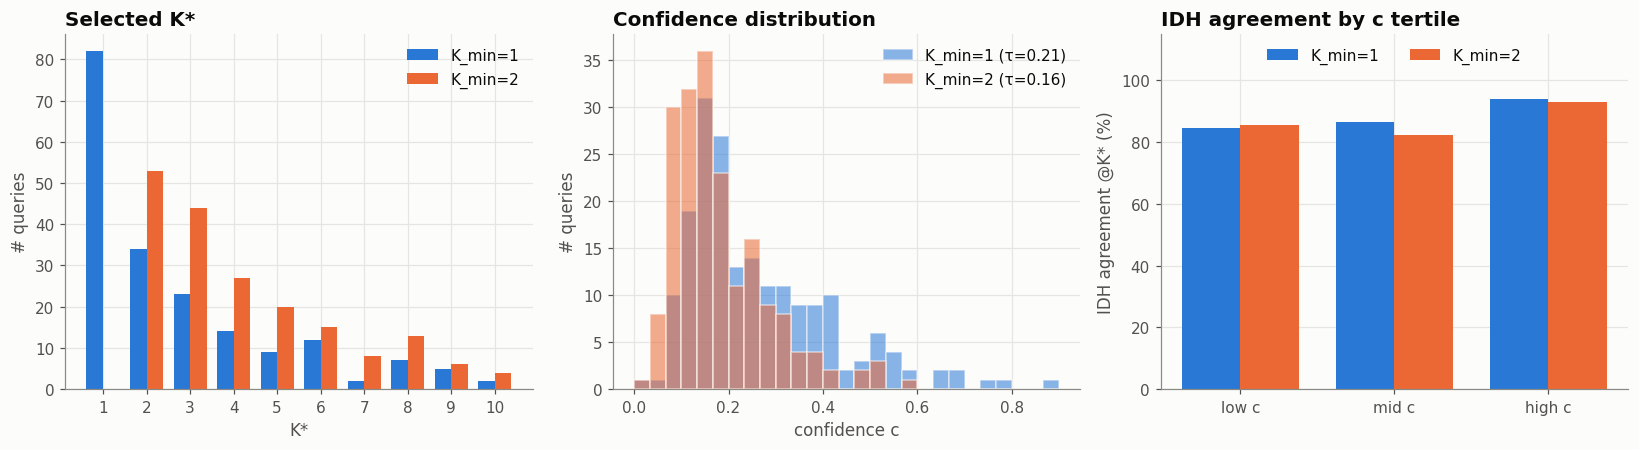

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ks = np.arange(1, K_MAX + 1)
for j, km in enumerate([1, 2]):
    r = ABL[km][0]
    cnt = r.k_star.value_counts().reindex(ks, fill_value=0)
    axes[0].bar(ks + (j - 0.5) * 0.38, cnt.values, width=0.38, color=SERIES[j], label=f"K_min={km}")
    axes[1].hist(r.c, bins=np.linspace(0, 0.9, 28), color=SERIES[j], alpha=0.55,
                 edgecolor=SURFACE, linewidth=1, label=f"K_min={km} (τ={ABL[km][1]:.2f})")
    t = tert.loc[f"K_min={km}"]
    axes[2].bar(np.arange(3) + (j - 0.5) * 0.38, t.idh_pK.values, width=0.38, color=SERIES[j],
                label=f"K_min={km}")
axes[0].set_xticks(ks); axes[0].set_xlabel("K*"); axes[0].set_ylabel("# queries")
axes[0].set_title("Selected K*"); axes[0].legend()
axes[1].set_xlabel("confidence c"); axes[1].set_ylabel("# queries")
axes[1].set_title("Confidence distribution"); axes[1].legend()
axes[2].set_xticks(np.arange(3), ["low c", "mid c", "high c"])
axes[2].set_ylim(0, 115); axes[2].set_yticks(range(0, 101, 20))
axes[2].set_ylabel("IDH agreement @K* (%)")
axes[2].set_title("IDH agreement by c tertile"); axes[2].legend(loc="upper center", ncol=2)
save(fig, "06_ablation_kmin")

## 8. 역할 분리: c는 K_min=1, K는 K_min=2

같은 유사도 곡선에서 틈 찾기를 두 번 한다.
- ① **c (프롬프트 선택)**: K_min=1 → Δ1(1등이 혼자 튀는 신호)을 유지
- ② **K (넘길 소견서 수)**: K_min=2 → 항상 2개 이상

세 설정을 비교한다. τ는 각 설정에서 c를 만드는 방식의 val median
(분리 방식은 c가 K_min=1과 같으므로 τ도 같다).

In [15]:
r1, tau1 = ABL[1]
r2, tau2 = ABL[2]
assert (r1.id.values == r2.id.values).all()
rs = r2.copy()                         # K와 품질 지표는 K_min=2 쪽
rs["c"] = r1.c.values                  # c는 K_min=1 쪽
rs["confident"] = rs.c >= tau1
rs["c_group"] = r1.c_group.values
SET = {"K_min=1": r1, "K_min=2": r2, "split (c:1, K:2)": rs}
TAU = {"K_min=1": tau1, "K_min=2": tau2, "split (c:1, K:2)": tau1}
rs.assign(c_kmin1=r1.c.values, k_kmin1=r1.k_star.values).to_csv(f"{OUT}/split_scores.csv", index=False)

rows = []
for nm, r in SET.items():
    for sp in ["val", "test", "all"]:
        x = r if sp == "all" else r[r.split == sp]
        conf, unc = x[x.confident], x[~x.confident]
        rows.append({"setting": nm, "split": sp, "n": len(x), "τ": TAU[nm],
                     "mean K": x.k_star.mean(), "K=1 %": (x.k_star == 1).mean() * 100,
                     "confident %": x.confident.mean() * 100,
                     "IDH@K": x.idh_pK.mean(), "label@K": x.lab_pK.mean(), "RepSim@K": x.rep_K.mean(),
                     "IDH conf": conf.idh_pK.mean(), "IDH unc": unc.idh_pK.mean(),
                     "IDH gap": conf.idh_pK.mean() - unc.idh_pK.mean(),
                     "ρ(c, IDH@K)": spearman(x.c, x.idh_pK)})
cmp = pd.DataFrame(rows).round(3)
cmp.to_csv(f"{OUT}/split_summary.csv", index=False)
cmp[cmp.split == "all"]

,setting,split,n,τ,mean K,K=1 %,confident %,IDH@K,label@K,RepSim@K,IDH conf,IDH unc,IDH gap,"ρ(c, IDH@K)"
2,K_min=1,all,190,0.214,2.774,43.158,49.474,88.36,79.069,0.524,93.085,83.733,9.352,0.150
5,K_min=2,all,190,0.155,4.158,0.000,52.105,87.04,78.250,0.527,89.268,84.616,4.651,0.028
8,"split (c:1, K:2)",all,190,0.214,4.158,0.000,49.474,87.04,78.250,0.527,91.207,82.960,8.247,0.076


In [16]:
# val / test 따로
cmp[cmp.split != "all"].set_index(["split", "setting"])[
    ["mean K", "confident %", "IDH@K", "label@K", "IDH conf", "IDH unc", "IDH gap"]]

,,mean K,confident %,IDH@K,label@K,IDH conf,IDH unc,IDH gap
split,setting,,,,,,,
val,K_min=1,2.978,50.0,93.821,81.321,96.296,91.346,4.951
test,K_min=1,2.590,49.0,83.444,77.042,90.136,77.015,13.121
val,K_min=2,4.000,50.0,92.697,80.091,93.519,91.875,1.644
test,K_min=2,4.300,54.0,81.949,76.594,85.725,77.516,8.210
val,"split (c:1, K:2)",4.000,50.0,92.697,80.091,95.741,89.653,6.088
test,"split (c:1, K:2)",4.300,49.0,81.949,76.594,87.043,77.054,9.989


In [17]:
# c 3등분 그룹별 (val+test)
tert3 = pd.concat({nm: r.groupby("c_group", observed=True).agg(
    n=("c", "size"), K_mean=("k_star", "mean"), idh_pK=("idh_pK", "mean"),
    lab_pK=("lab_pK", "mean")) for nm, r in SET.items()}).round(3)
tert3.to_csv(f"{OUT}/split_tertile.csv")
# 분리 방식에서 K가 늘어난 쿼리 (= K_min=1에서 K*=1이던 쿼리)
grow = rs.k_star.values != r1.k_star.values
print(f"K가 바뀐 쿼리: {grow.sum()} / {len(rs)}")
print(f"  그중 Confident: {rs.confident.values[grow].sum()}  "
      f"IDH@K  K_min=1(1개) {r1.idh_pK.values[grow].mean():.1f}% → split {rs.idh_pK.values[grow].mean():.1f}%")
tert3

K가 바뀐 쿼리: 82 / 190
  그중 Confident: 55  IDH@K  K_min=1(1개) 91.5% → split 88.4%


n  K_mean  idh_pK  lab_pK
                 c_group                            
K_min=1          low c    64   4.312  84.453  80.178
                 mid c    62   2.484  86.559  77.016
                 high c   64   1.516  94.010  79.948
K_min=2          low c    64   5.031  85.719  81.859
                 mid c    62   4.306  82.283  71.831
                 high c   64   3.141  92.969  80.859
split (c:1, K:2) low c    64   5.375  86.102  81.827
                 mid c    62   3.613  83.890  72.657
                 high c   64   3.469  91.029  80.091

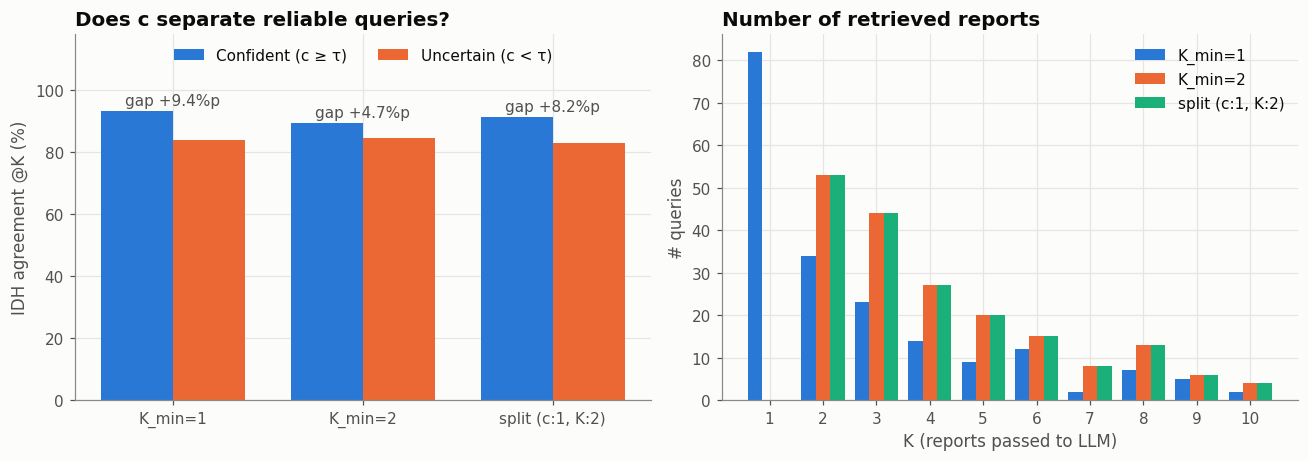

In [18]:
names = list(SET)
a = cmp[cmp.split == "all"].set_index("setting").loc[names]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
x = np.arange(len(names))
axes[0].bar(x - 0.19, a["IDH conf"], width=0.38, color=SERIES[0], label="Confident (c ≥ τ)")
axes[0].bar(x + 0.19, a["IDH unc"], width=0.38, color=SERIES[1], label="Uncertain (c < τ)")
for i, (cf, un) in enumerate(zip(a["IDH conf"], a["IDH unc"])):
    axes[0].annotate(f"gap {cf - un:+.1f}%p", xy=(i, max(cf, un) + 2), ha="center", color=TEXT2)
axes[0].set_xticks(x, names)
axes[0].set_ylim(0, 118); axes[0].set_yticks(range(0, 101, 20))
axes[0].set_ylabel("IDH agreement @K (%)")
axes[0].set_title("Does c separate reliable queries?")
axes[0].legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))

ks = np.arange(1, K_MAX + 1)
for j, nm in enumerate(names):
    cnt = SET[nm].k_star.value_counts().reindex(ks, fill_value=0)
    axes[1].bar(ks + (j - 1) * 0.27, cnt.values, width=0.27, color=SERIES[j], label=nm)
axes[1].set_xticks(ks)
axes[1].set_xlabel("K (reports passed to LLM)"); axes[1].set_ylabel("# queries")
axes[1].set_title("Number of retrieved reports")
axes[1].legend()
save(fig, "07_split_roles")